# Trojan Detection from Network Flow Features
Binary classification (**Benign** vs **Trojan**) of network flows using CICFlowMeter-style features and classic ML models.

**Pipeline:** load → clean → explore → train/evaluate several models → feature importance → conclusions.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

## 1. Load data

In [2]:
df = pd.read_csv('Trojan_Detection1.csv')
df.columns = df.columns.str.strip()          # column names contain stray spaces
print(df.shape)
df['Class'].value_counts()

(199, 86)


Class
Benign    110
Trojan     89
Name: count, dtype: int64

## 2. Clean data
Remove identifier columns (`Flow ID`, IPs, `Timestamp`, index). They identify *who* / *when*, not *how* traffic behaves, and would let the model memorise hosts instead of learning behaviour.

In [3]:
drop_cols = ['Unnamed: 0', 'Flow ID', 'Source IP', 'Destination IP', 'Timestamp']
X = df.drop(columns=drop_cols + ['Class'])
y = (df['Class'] == 'Trojan').astype(int)     # 1 = Trojan, 0 = Benign

X = X.replace([np.inf, -np.inf], np.nan)
print('Missing values:', int(X.isna().sum().sum()), '| Duplicate rows:', int(df.duplicated().sum()))
X = X.fillna(X.median())
X = X.loc[:, X.nunique() > 1]                  # drop constant columns
print('Features used:', X.shape[1])

Missing values: 0 | Duplicate rows: 0
Features used: 68


### Leakage check
The leftover `Unnamed: 0` column is the row index from the original, larger capture. Let's see what happens if it is *not* dropped:

In [4]:
rf_tmp = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE)
cv5 = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
leak = cross_validate(rf_tmp, df[['Unnamed: 0']], y, cv=cv5, scoring='accuracy')['test_score'].mean()
print(f"Accuracy using ONLY the row-index column: {leak:.1%}  <- leakage, must be excluded")

Accuracy using ONLY the row-index column: 100.0%  <- leakage, must be excluded


## 3. Exploratory analysis

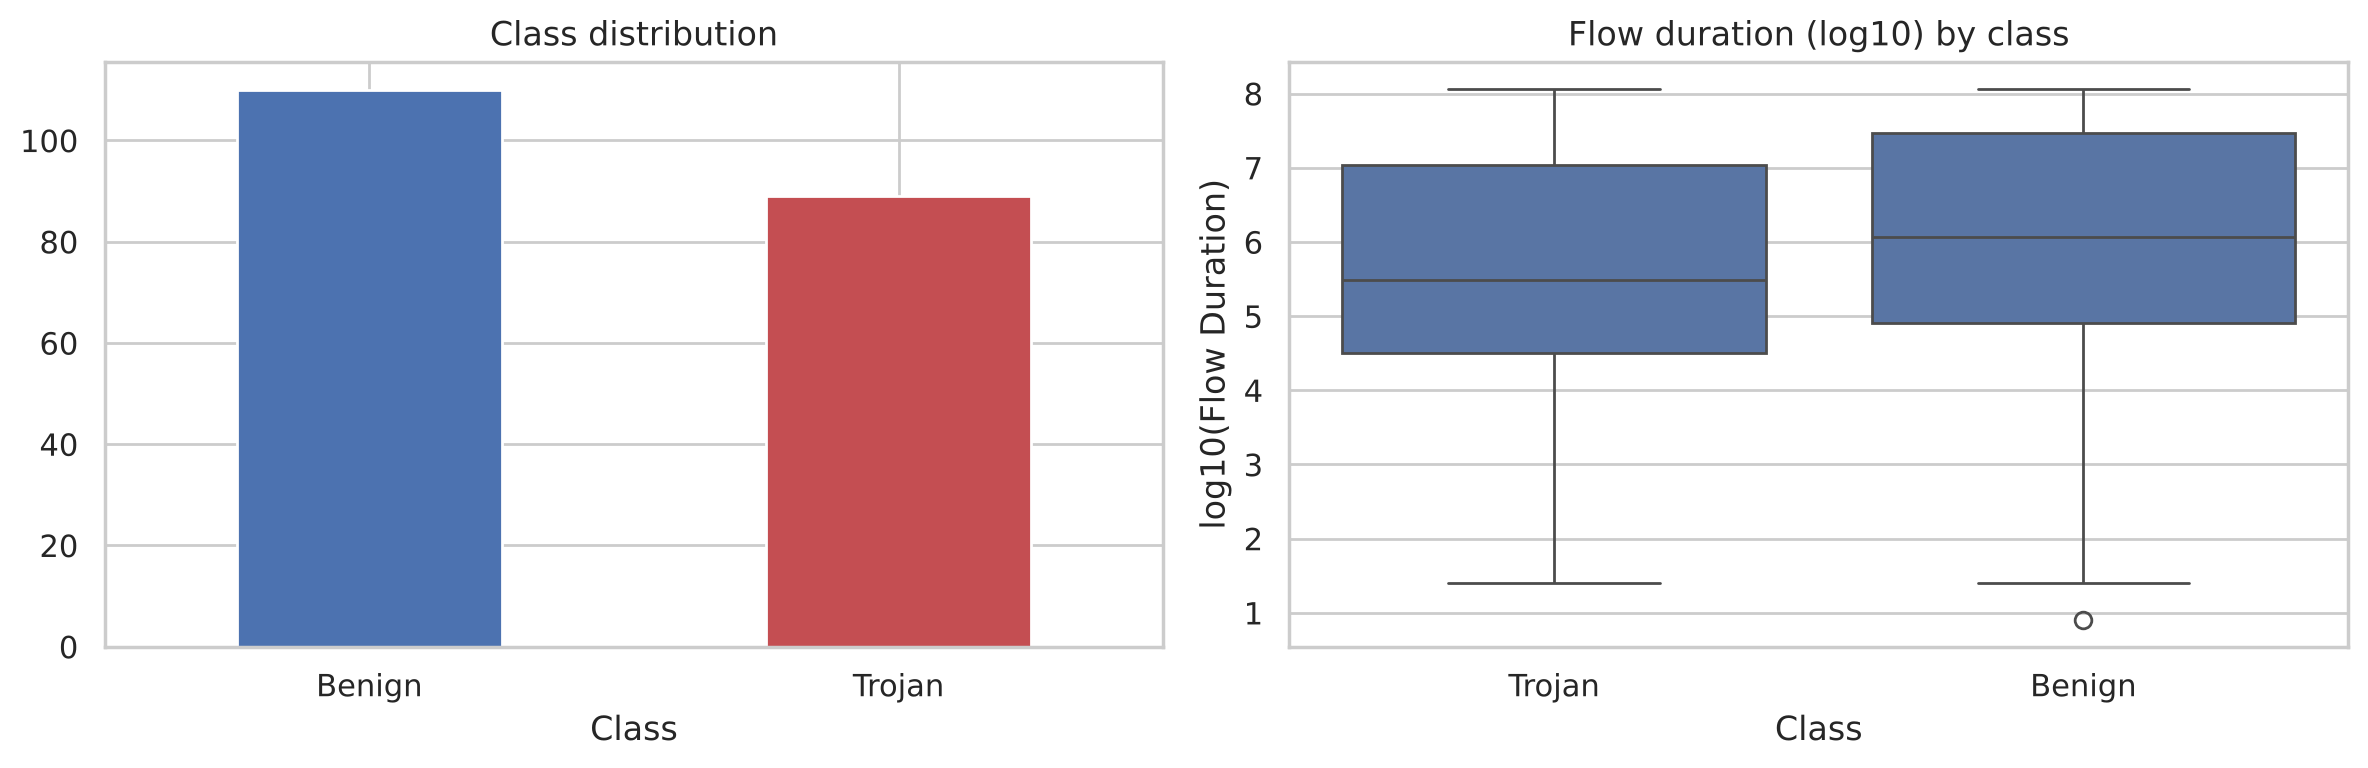

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df['Class'].value_counts().plot.bar(ax=ax[0], color=['#4C72B0', '#C44E52'], rot=0)
ax[0].set_title('Class distribution')
sns.boxplot(data=df, x='Class', y=np.log10(df['Flow Duration'] + 1), ax=ax[1])
ax[1].set_title('Flow duration (log10) by class'); ax[1].set_ylabel('log10(Flow Duration)')
plt.tight_layout(); plt.show()

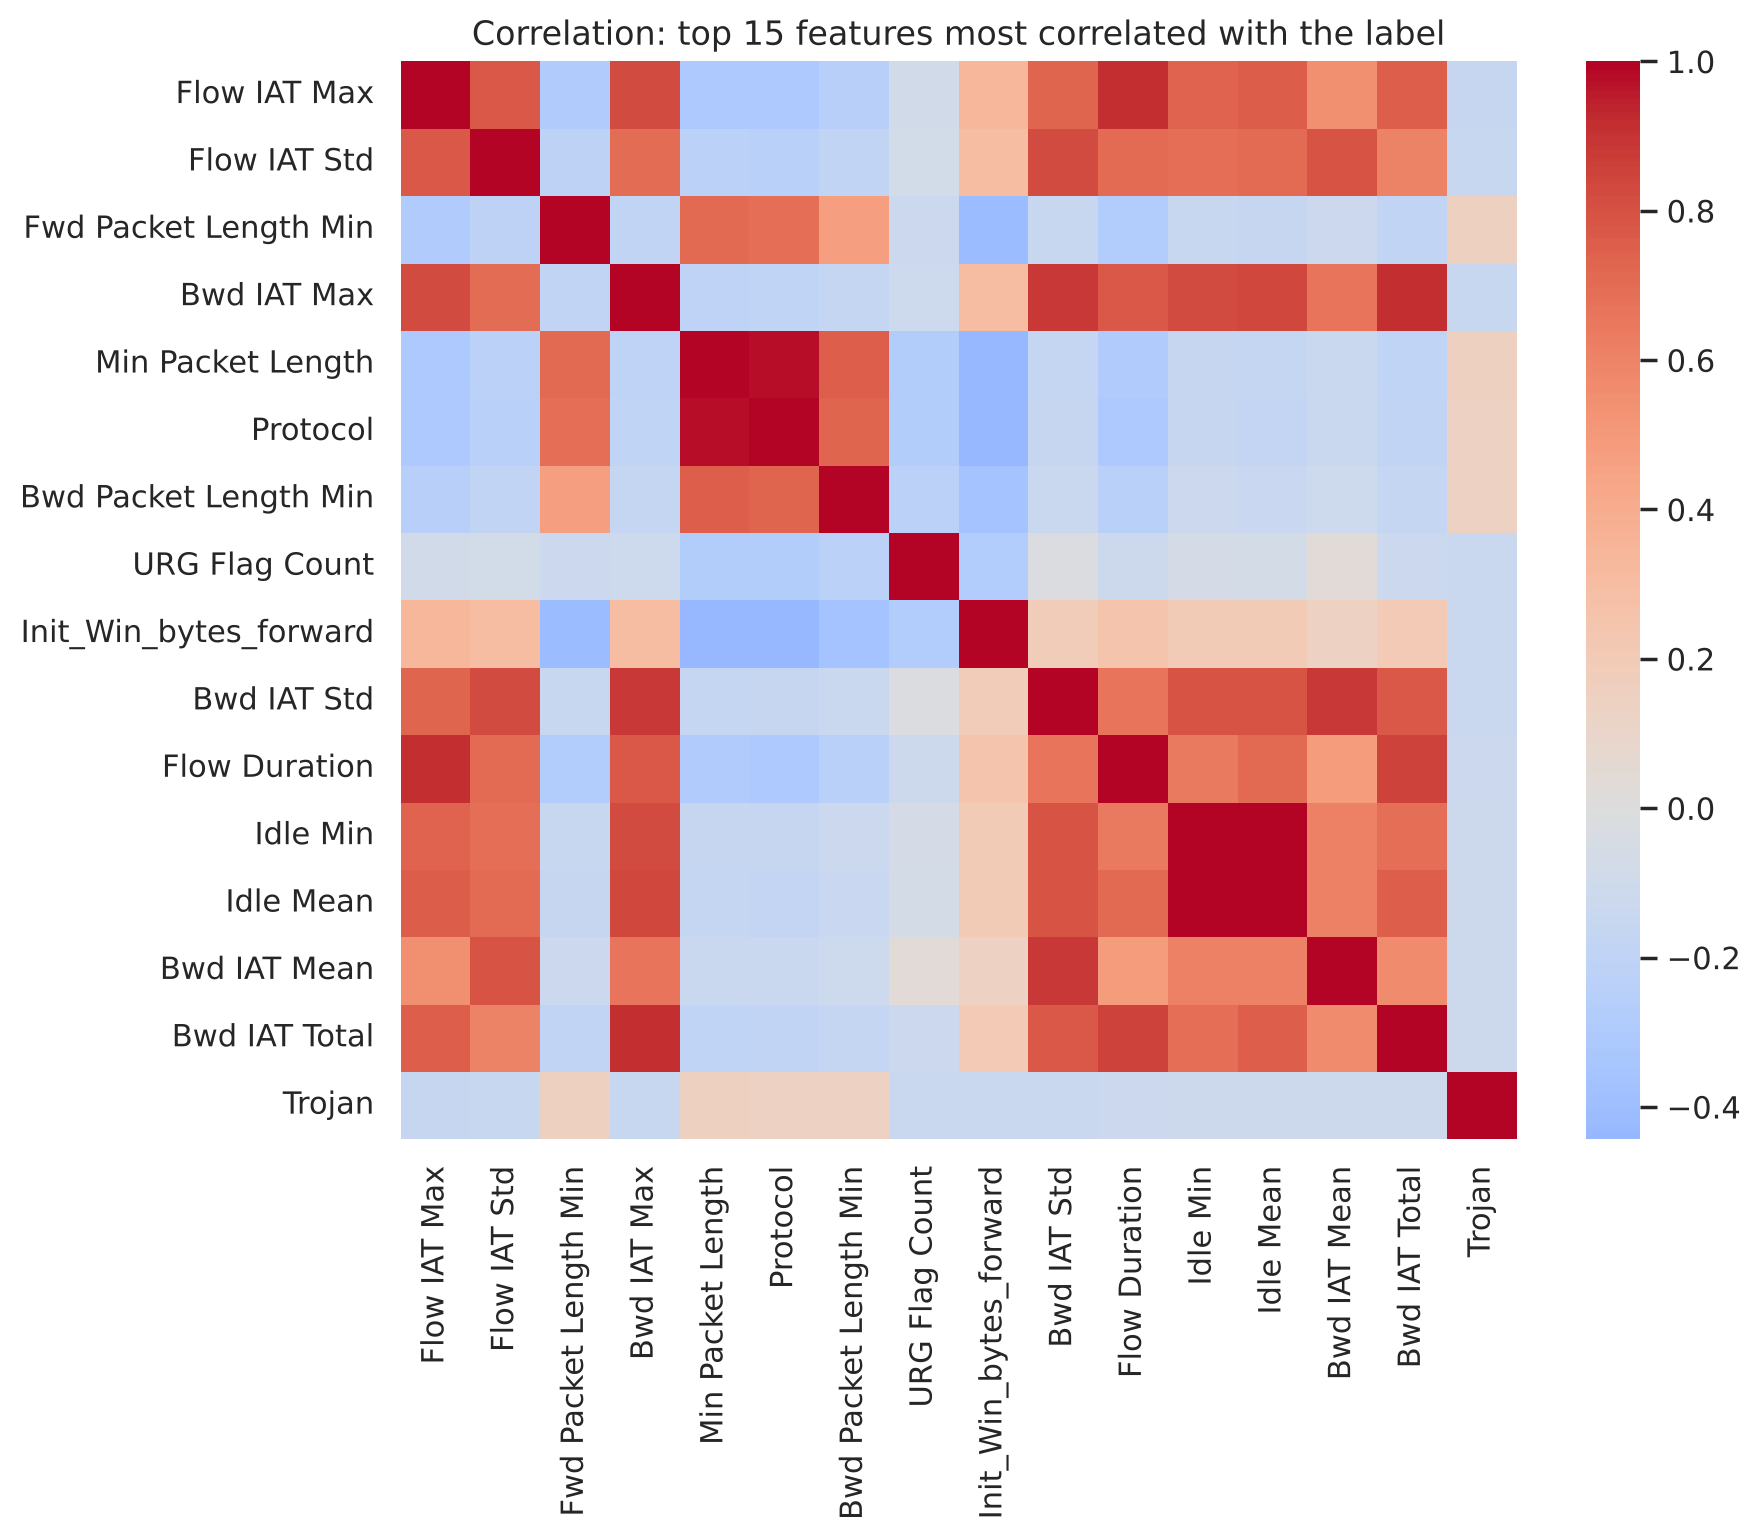

In [6]:
top = X.corrwith(y).abs().sort_values(ascending=False).head(15).index
plt.figure(figsize=(9, 7))
sns.heatmap(X[top].assign(Trojan=y).corr(), cmap='coolwarm', center=0, annot=False)
plt.title('Correlation: top 15 features most correlated with the label')
plt.show()

## 4. Model comparison (stratified 5-fold cross-validation)
With only ~200 flows, one train/test split is noisy, so models are compared with cross-validation on the training portion. A 30% hold-out set is kept for the final check.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE)

models = {
    'Decision Tree':       DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
    'Random Forest':       RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
    'Gradient Boosting':   GradientBoostingClassifier(random_state=RANDOM_STATE),
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
}
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, m in models.items():
    s = cross_validate(m, X_train, y_train, cv=cv, scoring=['accuracy', 'precision', 'recall', 'f1'])
    rows.append({'Model': name, **{k: s[f'test_{k}'].mean() for k in ['accuracy', 'precision', 'recall', 'f1']}})
results = pd.DataFrame(rows).set_index('Model').round(3).sort_values('f1', ascending=False)
results

,accuracy,precision,recall,f1
Model,,,,
Random Forest,0.490,0.408,0.356,0.379
Gradient Boosting,0.504,0.426,0.338,0.373
Logistic Regression,0.447,0.365,0.355,0.356
Decision Tree,0.511,0.376,0.329,0.317


In [8]:
from sklearn.dummy import DummyClassifier
base = cross_validate(DummyClassifier(strategy='most_frequent'), X_train, y_train, cv=cv, scoring='accuracy')['test_score'].mean()
print(f"Majority-class baseline accuracy: {base:.3f}")

Majority-class baseline accuracy: 0.554


## 5. Final evaluation on the hold-out test set

Best model (by CV F1): Random Forest
              precision    recall  f1-score   support

      Benign       0.56      0.55      0.55        33
      Trojan       0.46      0.48      0.47        27

    accuracy                           0.52        60
   macro avg       0.51      0.51      0.51        60
weighted avg       0.52      0.52      0.52        60



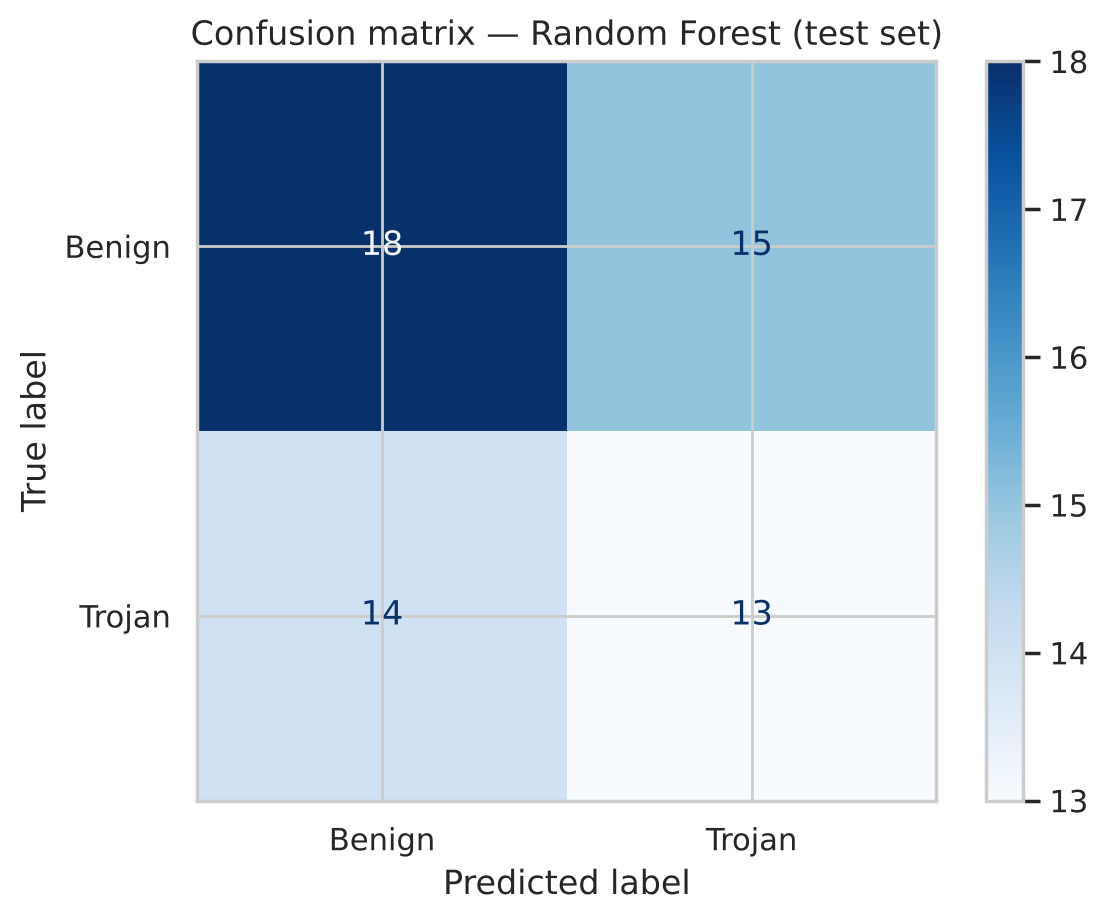

In [9]:
best_name = results.index[0]
best = models[best_name].fit(X_train, y_train)
y_pred = best.predict(X_test)
print('Best model (by CV F1):', best_name)
print(classification_report(y_test, y_pred, target_names=['Benign', 'Trojan']))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['Benign', 'Trojan'], cmap='Blues')
plt.title(f'Confusion matrix — {best_name} (test set)'); plt.show()

## 6. Which features matter?

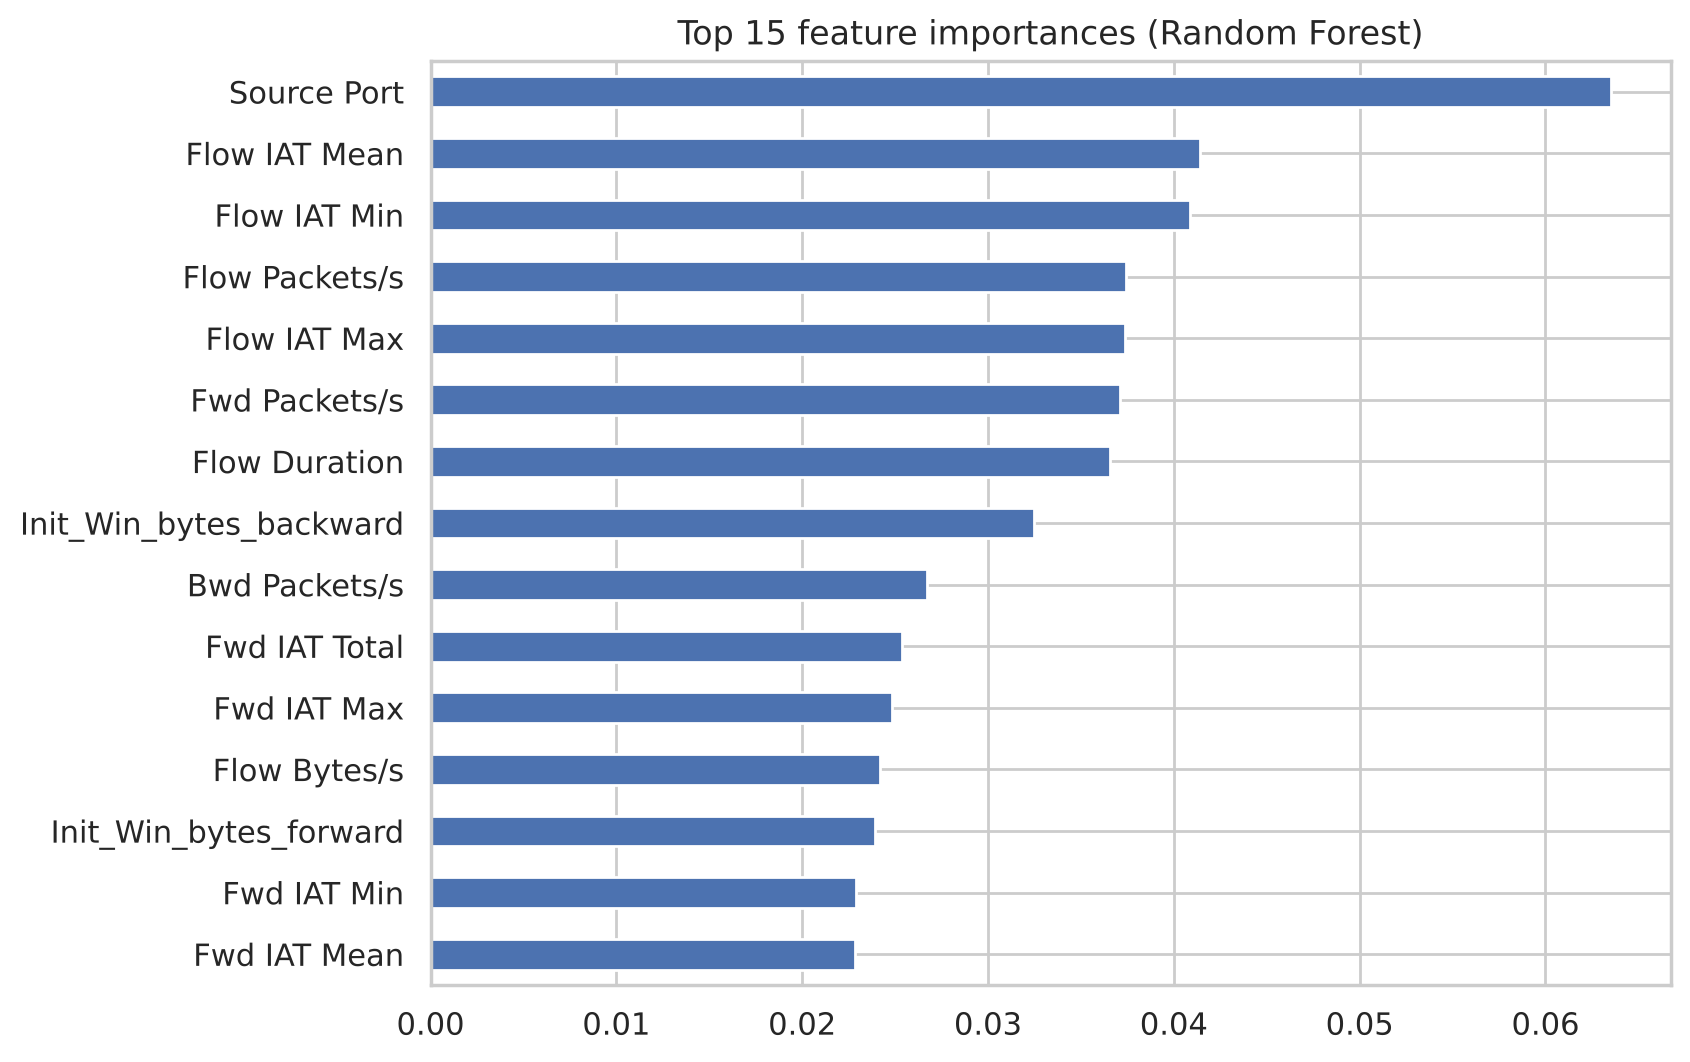

In [10]:
rf = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE).fit(X_train, y_train)
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values().tail(15)
imp.plot.barh(figsize=(8, 6), color='#4C72B0')
plt.title('Top 15 feature importances (Random Forest)'); plt.show()

## 7. Conclusions & limitations
- **Leakage matters:** the row-index column alone gives ~100% accuracy; the model must not see it. Using every column carelessly would report a misleadingly high score.
- **On this sample, flow-level features alone do not separate Trojan from benign traffic**: cross-validated accuracy/F1 stays near the majority-class baseline (section 4). This is a legitimate negative result, not a bug.
- **Likely reasons:** only 199 flows; flows come from a few hosts; Trojan behaviour may only show in longer sessions or per-host aggregated statistics.
- Flows from the same host appear in both classes and in both train and test, so even these modest scores may be optimistic.
- **Future work:** the full dataset (e.g. CIC-InvAndMal2017), host-grouped CV, per-host/time-window aggregation, hyperparameter tuning.